In [1]:
import os
import cv2
import json
import pyewts
import numpy as np
import onnxruntime as ort

from glob import glob
from tqdm import tqdm
from natsort import natsorted
from scipy.signal import find_peaks
from scipy.special import softmax
from Utils import optimize_countour
from Modules import PatchedLineDetection
import matplotlib.pyplot as plt

In [142]:
def show_image(image: np.array, cmap: str = "", axis="off") -> None:
    plt.figure(figsize=(24, 13))
    plt.axis(axis)
    
    if cmap != "":
        plt.imshow(image, cmap=cmap)
    else:
        plt.imshow(image)

def show_overlay(image: np.array, mask: np.array, alpha=0.4, axis="off"):
    plt.figure(figsize=(18, 9))
    plt.axis(axis)
    plt.imshow(image)
    plt.imshow(mask, alpha=alpha)

In [140]:
layout_config = "Models/LayoutModels/Modern/2024-1-30_8-16/model_config.json"

In [141]:
### modern layout v1 (unpatched)
class ModernLayoutDetection:
    """
    Handles layout detection
    Args:
        - config_file: json file with the following parameters:
            - onnx model file
            - image input width and height
            - classes

    """

    def __init__(
        self,
        config_file: str,
    ) -> None:
        self._config_file = config_file
        self._onnx_model_file = None
        self._input_width = 1024
        self._input_height = 320
        self._class_dict = None
        self._can_run = False
        self._inference = None
        # add other Execution Providers if applicable, see: https://onnxruntime.ai/docs/execution-providers
        self.execution_providers = ["CPUExecutionProvider", "CUDAExecutionProvider"]

        self._init()

    def _init(self) -> None:
        model_dir = os.path.dirname(self._config_file)
        _file = open(self._config_file)
        json_content = json.loads(_file.read())
        onnx_model_file = json_content["onnx-model"]
        model_file_path = f"{model_dir}/{onnx_model_file}"
        
        self._input_width = json_content["input_width"]
        self._input_height = json_content["input_height"]
        self._class_dict = json_content["classes"]
        
        print(model_file_path)
        self._inference = ort.InferenceSession(model_file_path, providers=self.execution_providers)
        print(self._inference)

    def predict(self, img_batch: np.array, class_threshold: float = 0.6) -> np.array:
        #print(img.shape)
        #prepared_img = self.prepare_single_img(img, image_width=self._input_width, image_height=self._input_height)
        img_batch = ort.OrtValue.ortvalue_from_numpy(img_batch)
        pred_batch = self._inference.run(None, {"input": img_batch})
        pred_batch = pred_batch[0]
        predictions = np.squeeze(pred_batch, axis=0)
        predictions = softmax(predictions, axis=0)
        predictions = np.transpose(predictions, axes=[1, 2, 0])

        predictions = predictions[:, :, 1:]  # removes the background class
        predictions = np.where(predictions > class_threshold, 1.0, 0)
        predictions *= 255

        predictions = predictions.astype(np.uint8)

        return predictions

In [143]:
input_width = 384
input_height = 512

layout_model = ModernLayoutDetection(layout_config)

Models/LayoutModels/Modern/2024-1-30_8-16/segmentation_model.onnx


In [ ]:
test_volume = f"E:/BDRC-Bucket/W2PD16805/images/W2PD16805-I4PD2815"
images = natsorted(glob(f"{test_volume}/*.tif"))

print(f"Images: {len(images)}")

Images: 589


In [ ]:
idx = 248
test_img = cv2.imread(images[idx])

show_image(test_img)

NameError: name 'cv2' is not defined

In [161]:
img = cv2.resize(test_img, (input_width, input_height))

In [162]:
def prepare_single_img(img: np.array, image_width: int = 1024, image_height: int = 320) -> np.array:
    print(img.dtype)
    print(f"resizing.....{image_width}:{image_height}")
    img = cv2.resize(img, (image_width, image_height))
    img = img.astype(np.float32)
    img /= 255.0
    img = np.expand_dims(img, axis=0)
    img = np.transpose(img, axes=[0, 3, 1, 2])
    
    return img

In [163]:
pred_img = prepare_single_img(test_img, image_width=input_width, image_height=input_height)
pred = layout_model.predict(pred_img)

uint8
resizing.....384:512


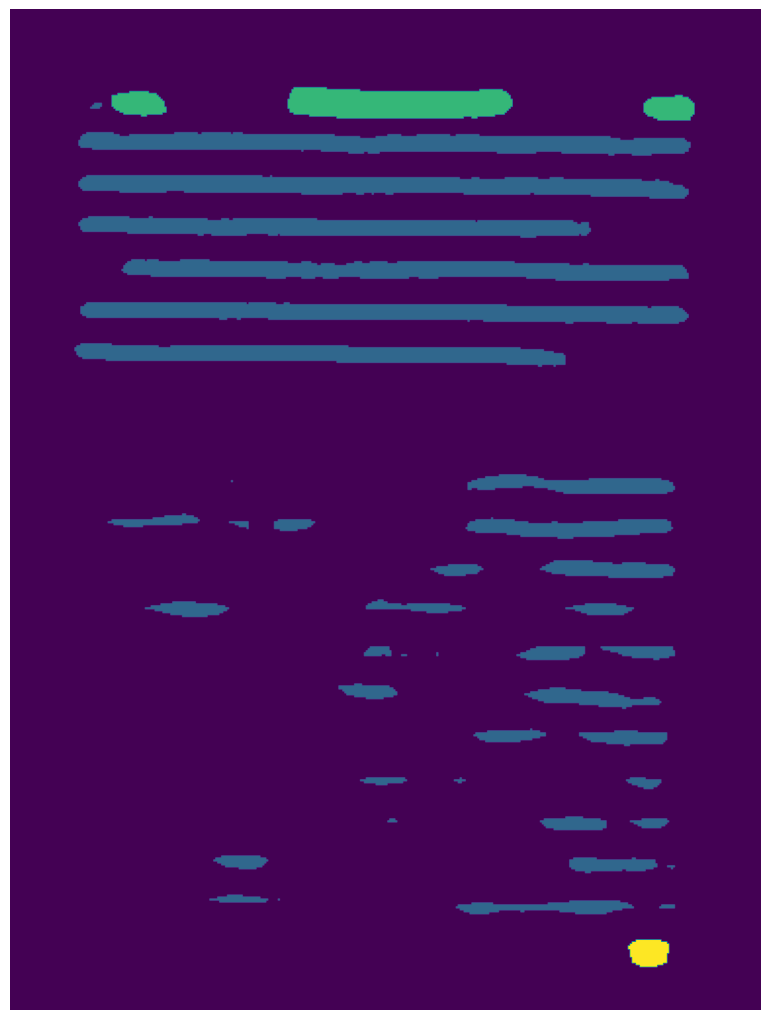

In [164]:
combined_output = np.argmax(pred, axis=-1)
combined_output = combined_output.astype(np.uint8)
combined_output = np.expand_dims(combined_output, axis=-1)
show_image(combined_output)

#### Line Detection

In [ ]:
line_model_config = "Models/LineModels/line_model_config.json"
line_inference = PatchedLineDetection(config_file=line_model_config, binarize_output=False, mode="cuda")